In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [2]:
sns.set_theme(style="whitegrid")

In [3]:
try:
    train_df = pd.read_csv('dataset/train.csv')
    test_df = pd.read_csv('dataset/test.csv')
    sample_sub = pd.read_csv('dataset/sample_submission.csv')
    print("Data loaded successfully.")
except FileNotFoundError as e:
    print(f"Error loading files: {e}")

Data loaded successfully.


In [4]:
print("--- Training Data Info ---")
train_df.info()

print("\n--- Missing Values in Training Data ---")
print(train_df.isnull().sum())

print("\n--- Summary Statistics (Numerical) ---")
print(train_df.describe())

--- Training Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134967 entries, 0 to 134966
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   title     134965 non-null  object
 1   tag       134967 non-null  object
 2   artist    134967 non-null  object
 3   year      134967 non-null  int64 
 4   views     134967 non-null  int64 
 5   features  134967 non-null  object
 6   lyrics    134967 non-null  object
 7   id        134967 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 8.2+ MB

--- Missing Values in Training Data ---
title       2
tag         0
artist      0
year        0
views       0
features    0
lyrics      0
id          0
dtype: int64

--- Summary Statistics (Numerical) ---
                year         views            id
count  134967.000000  1.349670e+05  1.349670e+05
mean     2009.467537  3.413344e+03  3.593871e+06
std        46.287743  4.192449e+04  2.323217e+06
min         1.000000 

C:\Users\HP\AppData\Local\Temp\ipykernel_20096\875871757.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, y='tag', order=train_df['tag'].value_counts().index, palette='viridis')


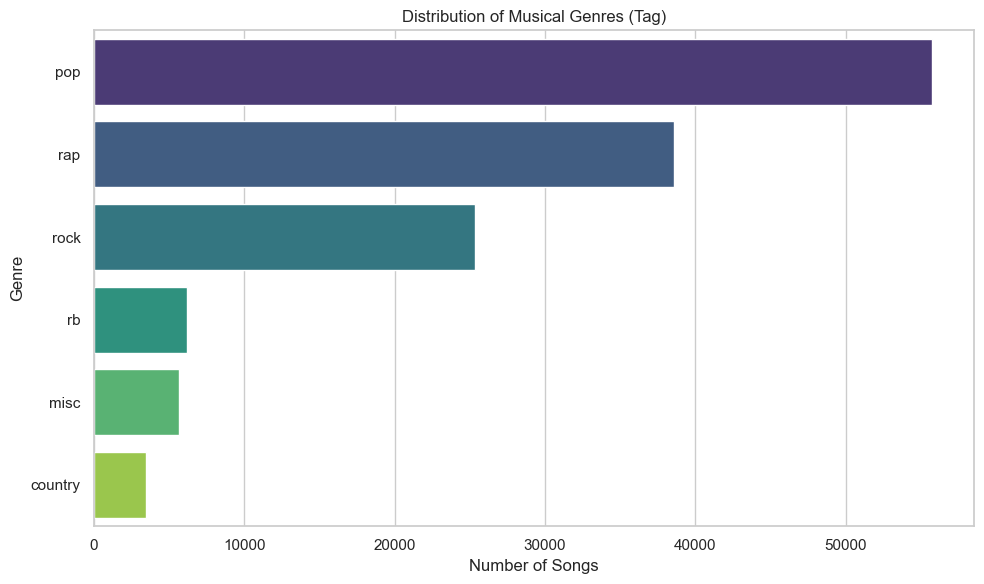

In [5]:
plt.figure(figsize=(10, 6))
sns.countplot(data=train_df, y='tag', order=train_df['tag'].value_counts().index, palette='viridis')
plt.title('Distribution of Musical Genres (Tag)')
plt.xlabel('Number of Songs')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_20096\1079022797.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x='tag', y='views', palette='Set2')


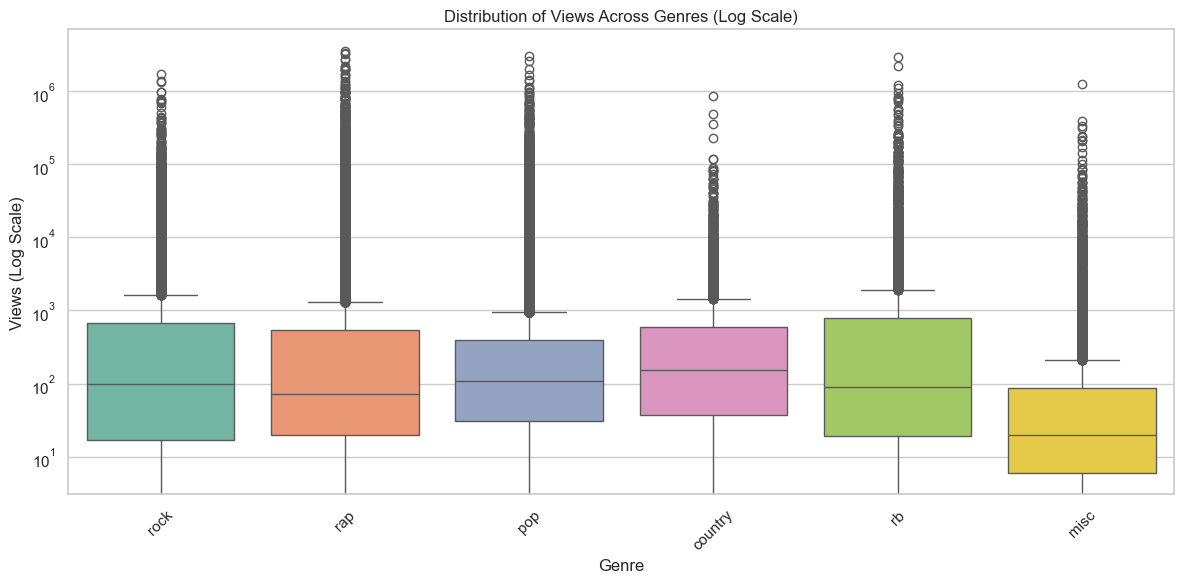

In [6]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=train_df, x='tag', y='views', palette='Set2')
plt.yscale('log') 
plt.title('Distribution of Views Across Genres (Log Scale)')
plt.xlabel('Genre')
plt.ylabel('Views (Log Scale)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

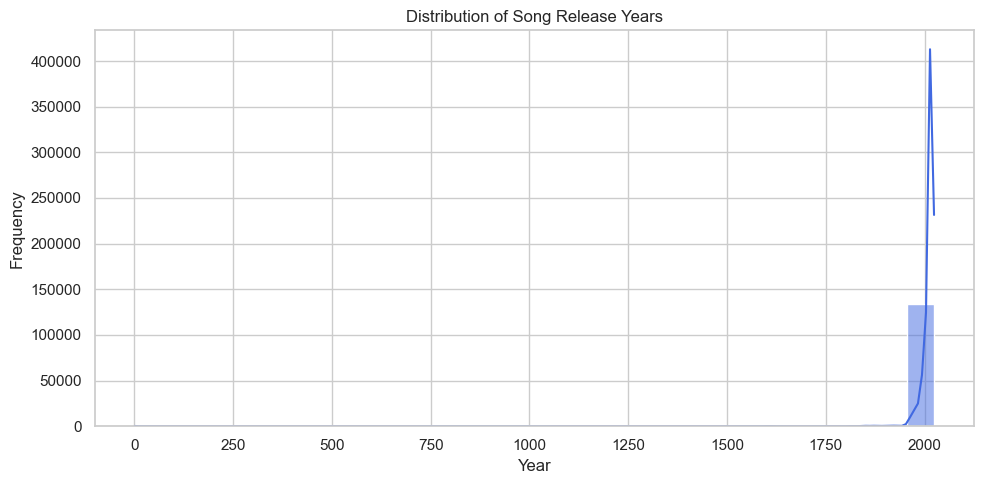

In [7]:
plt.figure(figsize=(10, 5))
sns.histplot(data=train_df, x='year', bins=30, kde=True, color='royalblue')
plt.title('Distribution of Song Release Years')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


--- Lyrics Word Count Statistics ---
count    134967.000000
mean        317.614017
std         451.526740
min           1.000000
25%         158.000000
50%         244.000000
75%         377.000000
max       18221.000000
Name: lyrics_word_count, dtype: float64


C:\Users\HP\AppData\Local\Temp\ipykernel_20096\858058645.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x='tag', y='lyrics_word_count', palette='muted')


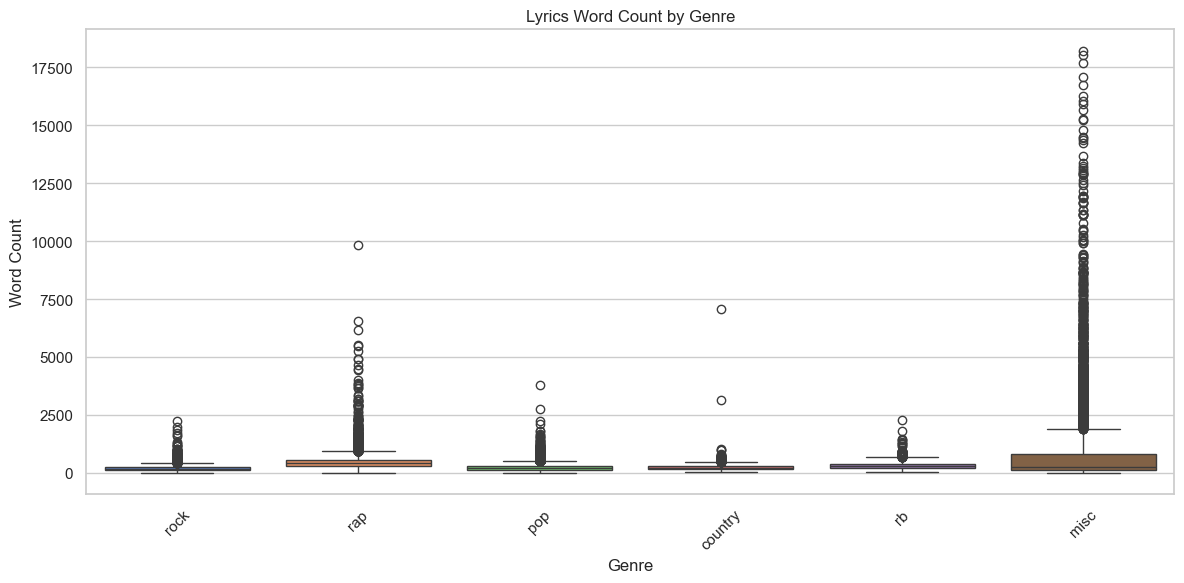

In [8]:
train_df['lyrics_length'] = train_df['lyrics'].astype(str).apply(len)
train_df['lyrics_word_count'] = train_df['lyrics'].astype(str).apply(lambda x: len(x.split()))

print("\n--- Lyrics Word Count Statistics ---")
print(train_df['lyrics_word_count'].describe())

plt.figure(figsize=(12, 6))
sns.boxplot(data=train_df, x='tag', y='lyrics_word_count', palette='muted')
plt.title('Lyrics Word Count by Genre')
plt.xlabel('Genre')
plt.ylabel('Word Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
def extract_section_tags(text):

    tags = re.findall(r'\[(.*?)\]', str(text))
    return tags

train_df['structure_tags'] = train_df['lyrics'].apply(extract_section_tags)
all_tags = [tag.lower() for sublist in train_df['structure_tags'] for tag in sublist]
tag_series = pd.Series(all_tags)

print("\n--- Most Common Song Structure Tags ---")
print(tag_series.value_counts().head(10))


--- Most Common Song Structure Tags ---
chorus        73582
verse 1       31644
verse 2       30041
?             20509
hook          14584
pre-chorus    14205
bridge        13972
outro         13844
intro         11536
verse          8555
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_20096\4050366224.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_artists.values, y=top_artists.index, palette='magma')


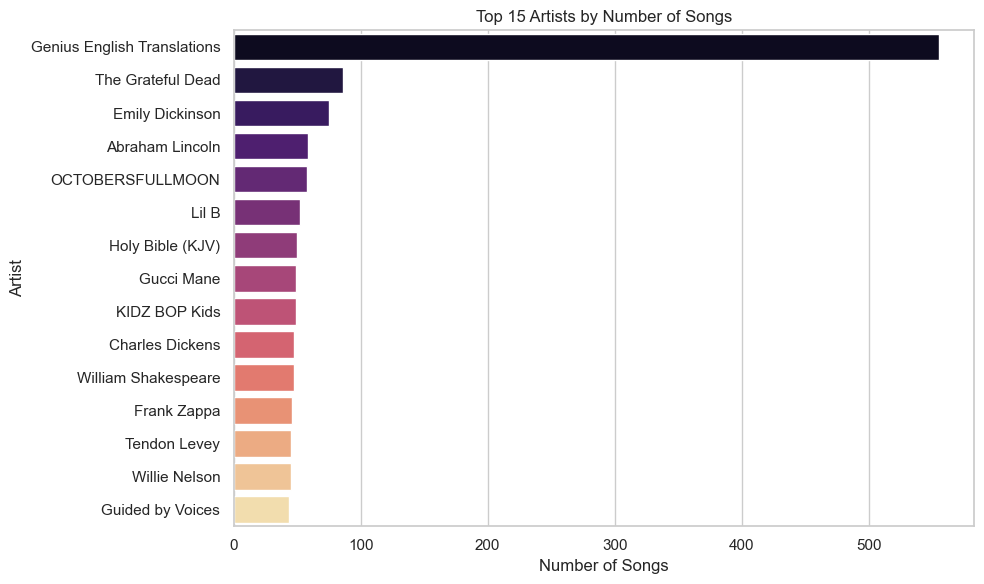

In [10]:
plt.figure(figsize=(10, 6))
top_artists = train_df['artist'].value_counts().head(15)
sns.barplot(x=top_artists.values, y=top_artists.index, palette='magma')
plt.title('Top 15 Artists by Number of Songs')
plt.xlabel('Number of Songs')
plt.ylabel('Artist')
plt.tight_layout()
plt.show()

In [11]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [12]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [13]:
def extract_chorus(lyrics):
    """Extracts text following a [Chorus] tag to create a dedicated feature."""
    if not isinstance(lyrics, str):
        return ""

    match = re.search(r'\[Chorus.*?\](.*?)(?=\[|$)', lyrics, flags=re.IGNORECASE | re.DOTALL)
    if match:
        return match.group(1).strip()
    return ""

train_df['chorus_only'] = train_df['lyrics'].apply(extract_chorus)

In [14]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text, remove_stopwords=True):
    """
    Cleans lyrics by lowercasing, removing structure tags, punctuation, and optionally stopwords.
    """
    if not isinstance(text, str):
        return ""
    
    text = text.lower()

    
    text = re.sub(r'\[.*?\]', ' ', text)
    
    
    text = text.replace('\n', ' ')
    
    
    text = re.sub(r'[^\w\s]', '', text)
    
    
    words = text.split()
    
    
    if remove_stopwords:
        words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
    else:
        words = [lemmatizer.lemmatize(w) for w in words]
        
    return ' '.join(words)

In [15]:
train_df['lyrics_clean_genre'] = train_df['lyrics'].apply(lambda x: clean_text(x, remove_stopwords=True))

train_df['lyrics_clean_sentiment'] = train_df['lyrics'].apply(lambda x: clean_text(x, remove_stopwords=False))

In [16]:
test_df['chorus_only'] = test_df['lyrics'].apply(extract_chorus)
test_df['lyrics_clean_genre'] = test_df['lyrics'].apply(lambda x: clean_text(x, remove_stopwords=True))
test_df['lyrics_clean_sentiment'] = test_df['lyrics'].apply(lambda x: clean_text(x, remove_stopwords=False))

In [17]:
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,   
    min_df=5,           
    max_df=0.85,         
    ngram_range=(1, 2)
)

In [18]:
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['lyrics_clean_genre'])
X_test_tfidf = tfidf_vectorizer.transform(test_df['lyrics_clean_genre'])

In [19]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()
y_train_encoded = le.fit_transform(train_df['tag'])
genre_classes = list(le.classes_)
print(f"Encoded classes: {genre_classes}")


X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_tfidf,
    y_train_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_train_encoded
)

print(f"Training samples: {X_tr.shape[0]:,}, Validation samples: {X_val.shape[0]:,}")

Encoded classes: ['country', 'misc', 'pop', 'rap', 'rb', 'rock']
Training samples: 107,973, Validation samples: 26,994


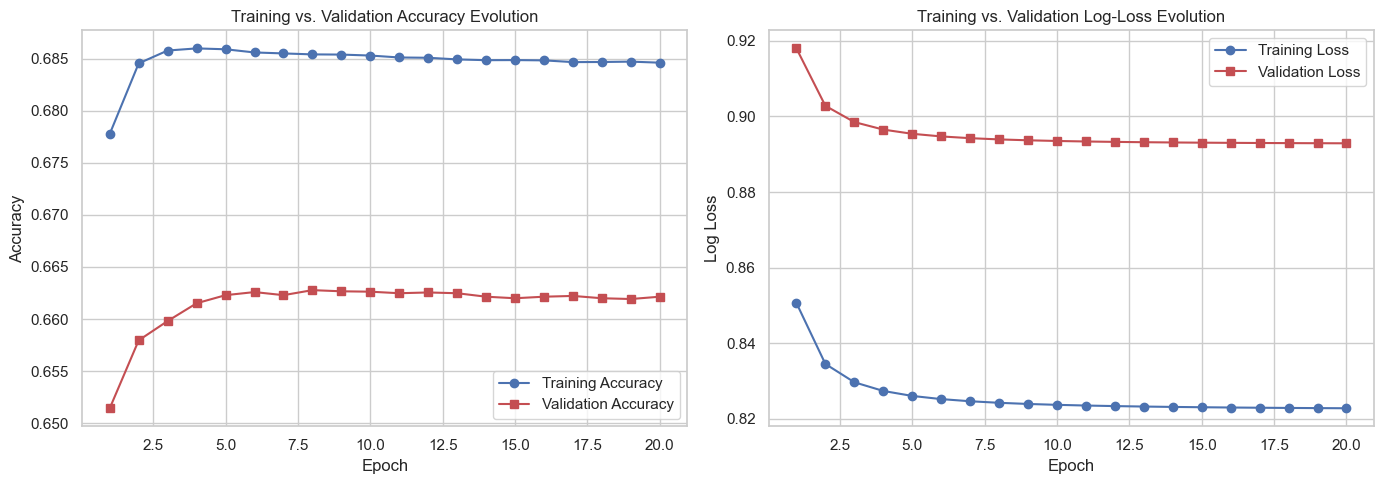

In [20]:
import numpy as np
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, log_loss

sgd_model = SGDClassifier(
    loss='log_loss',
    penalty='l2',
    alpha=1e-5,
    random_state=42
)

n_epochs = 20
train_acc_history = []
val_acc_history = []
train_loss_history = []
val_loss_history = []

all_classes = np.unique(y_tr)

for epoch in range(1, n_epochs + 1):
    sgd_model.partial_fit(X_tr, y_tr, classes=all_classes)
    
    y_tr_prob = sgd_model.predict_proba(X_tr)
    y_val_prob = sgd_model.predict_proba(X_val)
    
    y_tr_pred = np.argmax(y_tr_prob, axis=1)
    y_val_pred = np.argmax(y_val_prob, axis=1)
    
    train_acc_history.append(accuracy_score(y_tr, y_tr_pred))
    val_acc_history.append(accuracy_score(y_val, y_val_pred))
    train_loss_history.append(log_loss(y_tr, y_tr_prob))
    val_loss_history.append(log_loss(y_val, y_val_prob))


epochs_range = range(1, n_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, train_acc_history, 'b-o', label='Training Accuracy')
ax1.plot(epochs_range, val_acc_history, 'r-s', label='Validation Accuracy')
ax1.set_title('Training vs. Validation Accuracy Evolution')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

ax2.plot(epochs_range, train_loss_history, 'b-o', label='Training Loss')
ax2.plot(epochs_range, val_loss_history, 'r-s', label='Validation Loss')
ax2.set_title('Training vs. Validation Log-Loss Evolution')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Log Loss')
ax2.legend()

plt.tight_layout()
plt.show()

--- Validation Classification Report ---
              precision    recall  f1-score   support

     country       0.54      0.04      0.07       693
        misc       0.87      0.44      0.58      1128
         pop       0.59      0.86      0.70     11149
         rap       0.84      0.85      0.85      7717
          rb       0.36      0.02      0.05      1241
        rock       0.51      0.23      0.32      5066

    accuracy                           0.66     26994
   macro avg       0.62      0.41      0.43     26994
weighted avg       0.65      0.66      0.62     26994



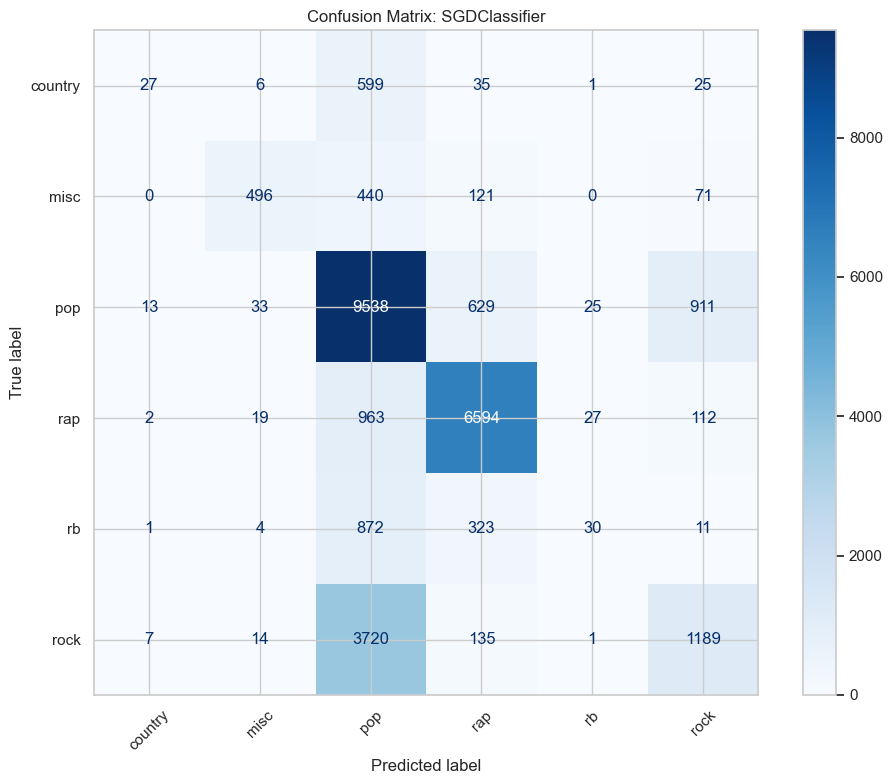

In [21]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_val_pred = np.argmax(sgd_model.predict_proba(X_val), axis=1)

print("--- Validation Classification Report ---")
print(classification_report(y_val, y_val_pred, target_names=genre_classes))

cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=genre_classes)
disp.plot(cmap='Blues', values_format='d', ax=plt.gca())
plt.title('Confusion Matrix: SGDClassifier')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...


Calculating sentiment scores. This may take a moment...


C:\Users\HP\AppData\Local\Temp\ipykernel_20096\4202488526.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x='tag', y='sentiment_score', palette='coolwarm')


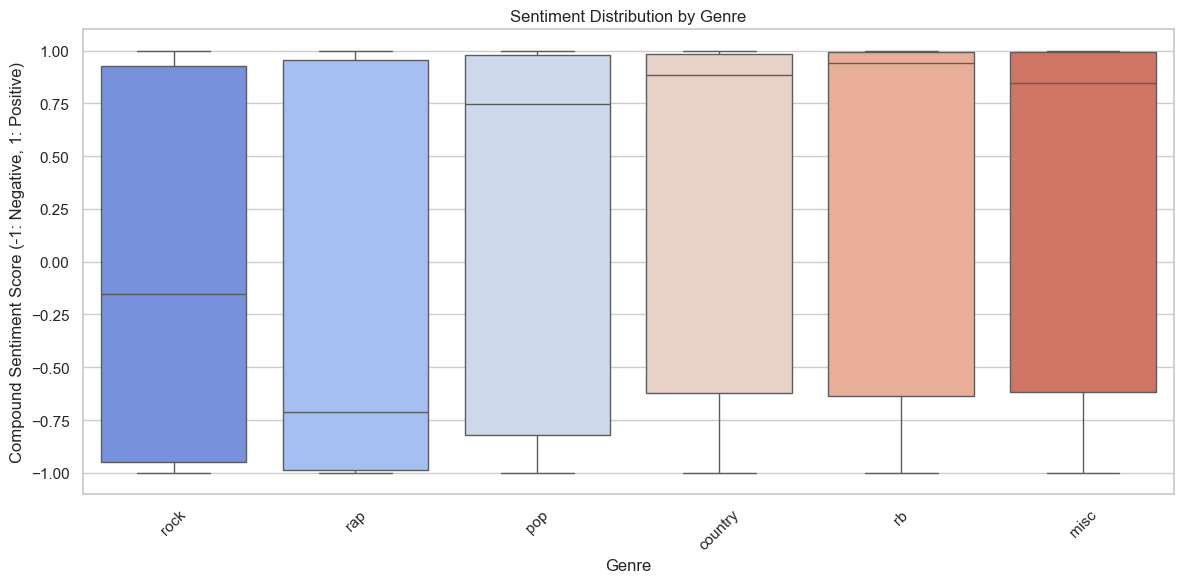

In [22]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

def get_sentiment(text):
    if not isinstance(text, str):
        return 0.0
    return sia.polarity_scores(text)['compound']

print("Calculating sentiment scores. This may take a moment...")
train_df['sentiment_score'] = train_df['lyrics_clean_sentiment'].apply(get_sentiment)

plt.figure(figsize=(12, 6))
sns.boxplot(data=train_df, x='tag', y='sentiment_score', palette='coolwarm')
plt.title('Sentiment Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('Compound Sentiment Score (-1: Negative, 1: Positive)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()